<a href="https://colab.research.google.com/github/mostafamoali57-spec/petrol-analsis20-26/blob/main/customer-churn-analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import StandardScaler, LabelEncoder
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12


#  Data Preprocessing

In [ ]:

df = pd.read_csv(r"/content/Customer-Churn.csv")
print("First 5 rows before preprocessing:")
print(df.head())

print("\nDataset information:")
print(df.info())

df.drop(columns=["customerID"], inplace=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
df.dropna(inplace=True)

df["Churn"] = df["Churn"].map({"Yes":1, "No":0})

First 5 rows before preprocessing:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV S

# Visualization

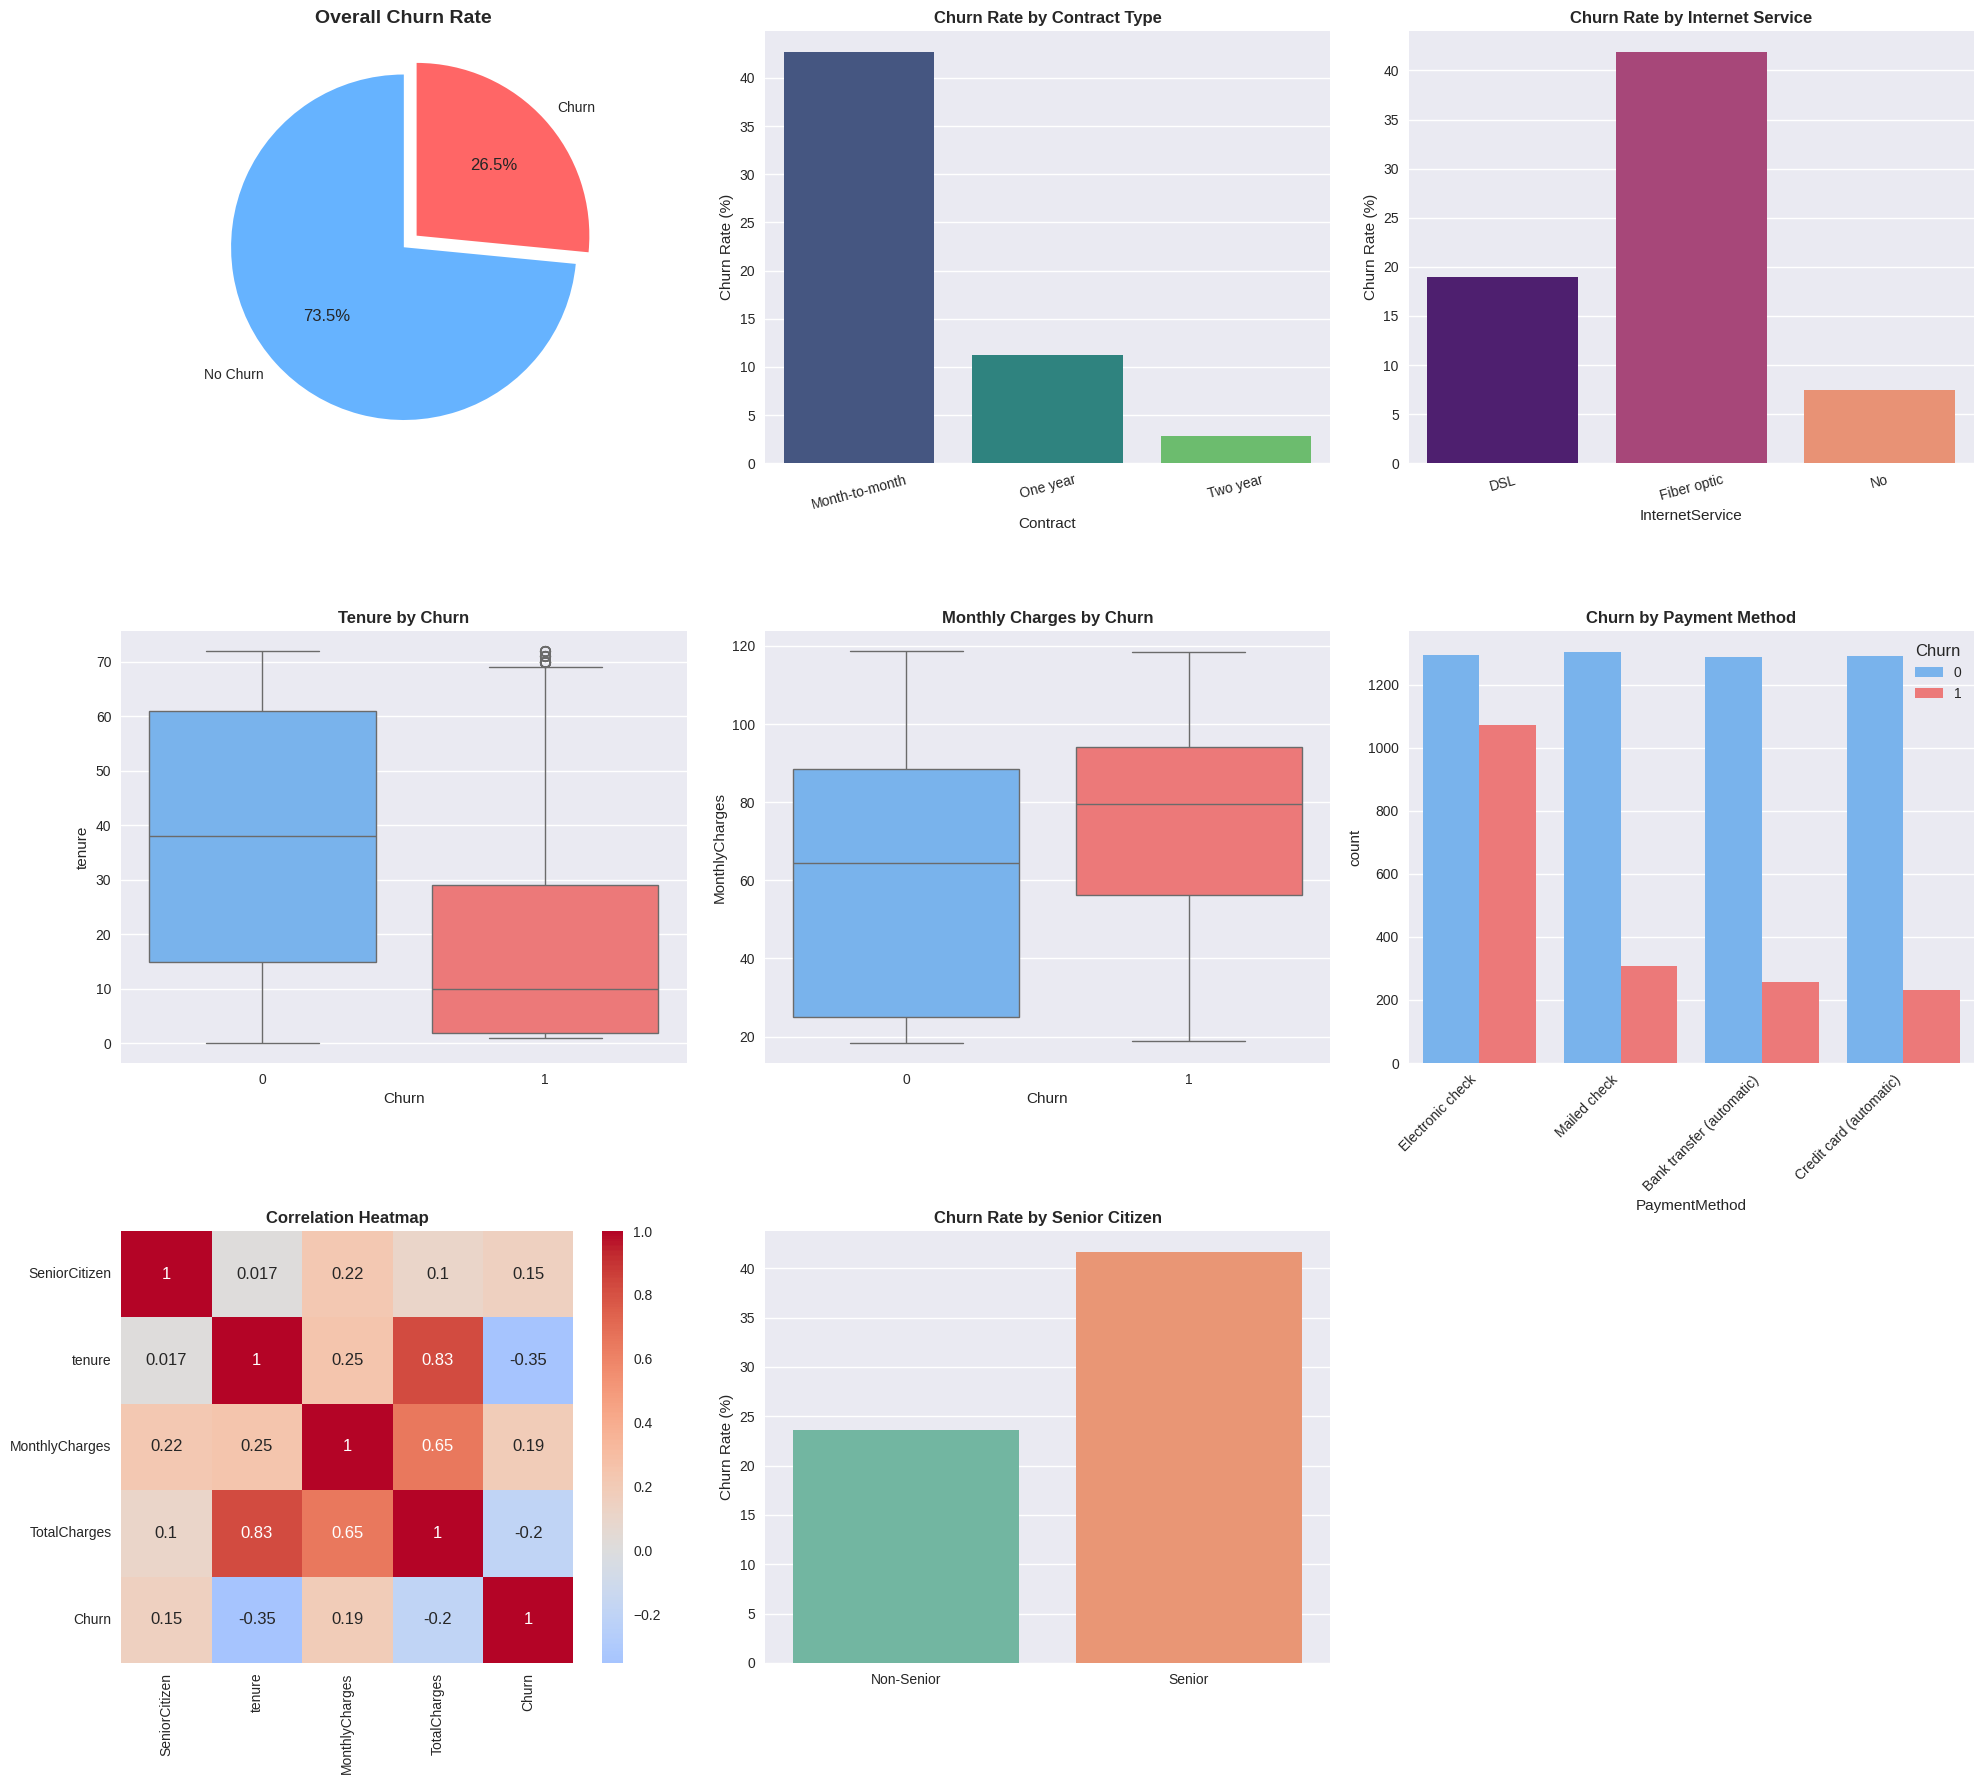

In [ ]:
fig = plt.figure(figsize=(20, 18))

# 1. Overall Churn Rate (Pie Chart)
ax1 = plt.subplot(3, 3, 1)
churn_rate = df['Churn'].value_counts(normalize=True) * 100
ax1.pie(churn_rate, labels=['No Churn', 'Churn'], autopct='%1.1f%%',
        colors=['#66b3ff', '#ff6666'], startangle=90, explode=(0, 0.1))
ax1.set_title('Overall Churn Rate', fontsize=14, fontweight='bold')

# 2. Churn by Contract Type
ax2 = plt.subplot(3, 3, 2)
contract_churn = df.groupby('Contract')['Churn'].mean() * 100
sns.barplot(x=contract_churn.index, y=contract_churn.values, palette='viridis', ax=ax2)
ax2.set_title('Churn Rate by Contract Type', fontsize=12, fontweight='bold')
ax2.set_ylabel('Churn Rate (%)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=15)

# 3. Churn by Internet Service
ax3 = plt.subplot(3, 3, 3)
internet_churn = df.groupby('InternetService')['Churn'].mean() * 100
sns.barplot(x=internet_churn.index, y=internet_churn.values, palette='magma', ax=ax3)
ax3.set_title('Churn Rate by Internet Service', fontsize=12, fontweight='bold')
ax3.set_ylabel('Churn Rate (%)')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=15)

# 4. Tenure vs Churn (Boxplot)
ax4 = plt.subplot(3, 3, 4)
sns.boxplot(x='Churn', y='tenure', data=df, palette=['#66b3ff', '#ff6666'], ax=ax4)
ax4.set_title('Tenure by Churn', fontsize=12, fontweight='bold')

# 5. Monthly Charges vs Churn (Boxplot)
ax5 = plt.subplot(3, 3, 5)
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette=['#66b3ff', '#ff6666'], ax=ax5)
ax5.set_title('Monthly Charges by Churn', fontsize=12, fontweight='bold')

# 6. Payment Method vs Churn
ax6 = plt.subplot(3, 3, 6)
sns.countplot(x='PaymentMethod', hue='Churn', data=df, palette=['#66b3ff', '#ff6666'], ax=ax6)
ax6.set_title('Churn by Payment Method', fontsize=12, fontweight='bold')
ax6.set_xticklabels(ax6.get_xticklabels(), rotation=45, ha='right')

# 7. Correlation Heatmap
ax7 = plt.subplot(3, 3, 7)
numeric_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=ax7)
ax7.set_title('Correlation Heatmap', fontsize=12, fontweight='bold')

# 8. Senior Citizen vs Churn
ax8 = plt.subplot(3, 3, 8)
senior_churn = df.groupby('SeniorCitizen')['Churn'].mean() * 100
sns.barplot(x=['Non-Senior', 'Senior'], y=senior_churn.values, palette='Set2', ax=ax8)
ax8.set_title('Churn Rate by Senior Citizen', fontsize=12, fontweight='bold')
ax8.set_ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

# segmentation

In [ ]:
features = df[['tenure', 'MonthlyCharges', 'TotalCharges']]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [ ]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

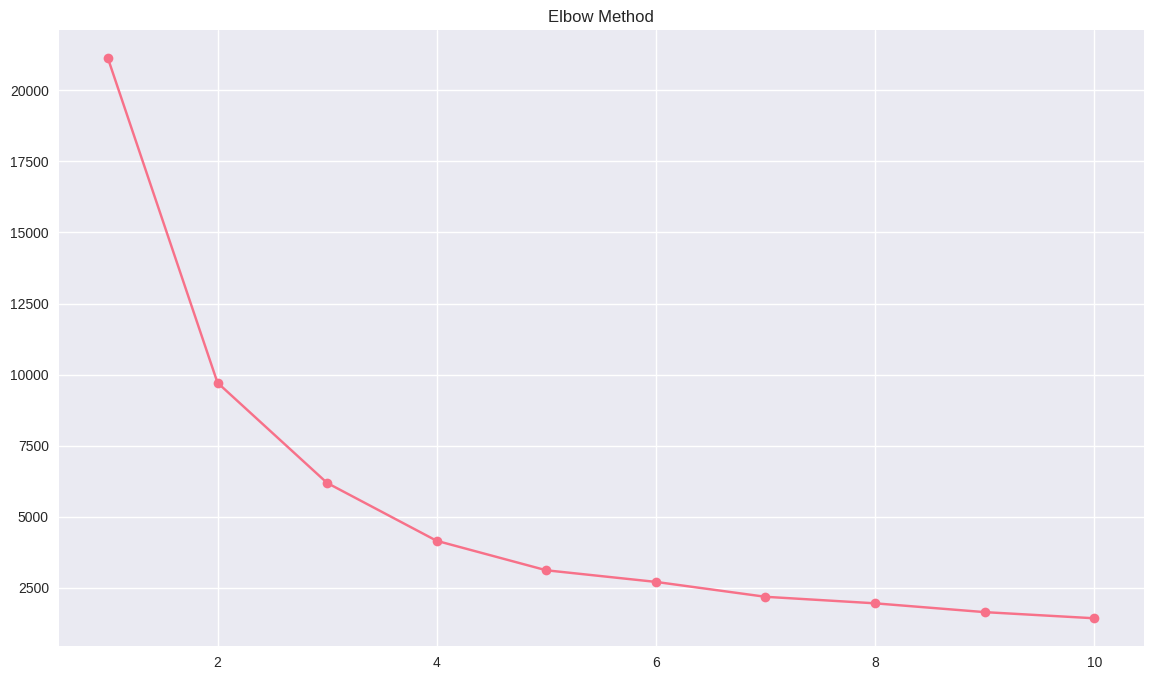

In [ ]:
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Segment'] = kmeans.fit_predict(scaled_features)

In [ ]:
analysis = df.groupby('Segment').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean',
    'Churn': lambda x: (x == 1).mean() * 100
    # نحسب نسبة المئوية للعملاء الذين غادروا الشركة (Churn) في كل مجموعة.
})
print(analysis)

            tenure  MonthlyCharges      Churn
Segment                                      
0        13.267164       75.073619  47.089552
1        58.572273       89.672432  15.363636
2        29.392048       26.648151  12.436431


# A\B testing

In [ ]:
df.groupby("TechSupport")["Churn"].mean()*100

,Churn
TechSupport,
No,41.635474
No internet service,7.404980
Yes,15.166341


In [ ]:
df.groupby("Contract")["Churn"].mean()*100

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


In [ ]:
df["charge_level"] = pd.cut(df["MonthlyCharges"], bins=3)
df.groupby(["charge_level", "TechSupport"])["Churn"].mean()*100

charge_level     TechSupport        
(18.15, 51.75]   No                     36.676218
                 No internet service     7.404980
                 Yes                    14.977974
(51.75, 85.25]   No                     41.796875
                 No internet service          NaN
                 Yes                    11.074197
(85.25, 118.75]  No                     44.229217
                 No internet service          NaN
                 Yes                    19.256018
Name: Churn, dtype: float64

# Text Classification

In [ ]:
def row_to_text(row):
    text = []

    # Contract
    text.append(f"{row['Contract'].replace('-', ' ')} contract")

    # Tenure
    tenure = row['tenure']
    if tenure < 3:
        text.append("extremely short tenure high risk")
    elif tenure < 12:
        text.append("short tenure churn risk")
    elif tenure < 24:
        text.append("medium tenure")
    else:
        text.append("long tenure loyal")

    # Monthly Charges
    charges = row['MonthlyCharges']
    if charges < 35:
        text.append("low charges")
    elif charges < 70:
        text.append("medium charges")
    else:
        text.append("high charges expensive")

    # other features
    if row['TechSupport'] == 'No':
        text.append("no tech support problem")
    if row['OnlineSecurity'] == 'No':
        text.append("no security risk")
    if row['InternetService'] == 'Fiber optic':
        text.append("fiber optic expensive fast")
    if row['SeniorCitizen'] == 1:
        text.append("senior citizen sensitive")
    if row['PaperlessBilling'] == 'Yes':
        text.append("paperless billing")
    if "electronic check" in str(row['PaymentMethod']).lower():
        text.append("electronic check risky payment")

    return " ".join(text)

df['text'] = df.apply(row_to_text, axis=1)
df['label'] = df['Churn']


vectorizer = TfidfVectorizer(
    max_features=2000,
    ngram_range=(1, 3),
    stop_words='english'
)

X = vectorizer.fit_transform(df['text'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


param_grid = {
    'C': [0.1, 1, 5, 10]
}

model = GridSearchCV(
    LinearSVC(class_weight='balanced'),
    param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Best Params:", model.best_params_)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Best Params: {'C': 5}
Accuracy: 0.731

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.73      0.75      1409


Confusion Matrix:
[[737 298]
 [ 81 293]]


In [ ]:
df['text']

,text
0,Month to month contract extremely short tenure...
1,One year contract long tenure loyal medium cha...
2,Month to month contract extremely short tenure...
3,One year contract long tenure loyal medium cha...
4,Month to month contract extremely short tenure...
...,...
7038,One year contract long tenure loyal high charg...
7039,One year contract long tenure loyal high charg...
7040,Month to month contract short tenure churn ris...
7041,Month to month contract short tenure churn ris...


#  Customer Churn Insights & Recommendations

---

##  Insight 1: New customers with monthly contracts are the highest risk

###  Observation
Customers with low tenure + month-to-month contracts show the highest churn rates.

###  Why it happens
- No long-term commitment  
- Customers are still testing the service  
- Easy to leave at any time  

###  Recommendation
- Offer onboarding discounts for the first 2–3 months  
- Provide early engagement (welcome calls, support follow-ups)  
- Encourage switching to longer contracts with incentives  

---

##  Insight 2: High-paying customers without Tech Support are very likely to churn

###  Observation
Customers with high MonthlyCharges + no TechSupport have significantly higher churn.

###  Why it happens
- Customers feel they are paying more but receiving less value  
- Lack of support increases frustration  

###  Recommendation
- Bundle free or discounted TechSupport for high-paying customers  
- Improve service quality for premium users  
- Create premium support tiers  

---

##  Insight 3: Long-term contracts significantly reduce churn

###  Observation
Customers with 1-year or 2-year contracts have much lower churn rates.

###  Why it happens
- Contract commitment reduces switching  
- Customers are more invested  

###  Recommendation
- Promote long-term plans with:  
  - Discounts  
  - Loyalty rewards  
- Use targeted campaigns to convert monthly users to yearly plans  

---

##  Insight 4: Customers with Fiber Optic internet tend to churn more

###  Observation
Fiber optic users show higher churn compared to DSL.

###  Why it happens
- Higher pricing  
- Possible service quality issues or expectations mismatch  

###  Recommendation
- Re-evaluate pricing vs value  
- Improve service reliability  
- Offer bundles or added benefits for fiber users  

---